# 임베딩과 의미 유사도

**이 노트북에서 할 일**

1. 문장 네 개를 임베딩 모델에 넣어, 문장마다 숫자 384개로 된 목록(벡터)을 만듭니다.
2. 두 벡터가 가리키는 방향이 얼마나 비슷한지, 코사인 유사도를 직접 만든 함수로 계산합니다.
3. 낱말 하나를 바꾸거나 부정문으로 바꿔, 유사도가 뜻의 차이를 어디까지 보여 주는지 확인합니다.

**준비물** — API 키는 필요 없습니다. 인터넷 서비스의 모델을 부르지 않고, 내 컴퓨터에서 임베딩 모델을 실행합니다.
그래서 비용은 들지 않습니다. 문장을 벡터로 바꾸는 메서드 `encode()`는 모두 5번 실행합니다.

실행 시간은 1분 안팎입니다. 첫 실행에서는 Hugging Face 사이트에서 모델 파일을 내려받으므로 인터넷 연결이 필요합니다.
교재 실행 컴퓨터에서 받은 모델 파일은 합쳐 약 500MB였습니다.

**기준 버전** — 실습 폴더에 고정한 sentence-transformers 5.1.1을 씁니다.
함께 고정한 transformers는 4.56.2, torch는 2.8.0, numpy는 2.3.3입니다.
모델은 `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`이고, 판 번호(revision)를 `e8f8c211226b894fcb81acc59f3b34ba3efd5f42`로 고정해 받습니다.


교재 출력은 Linux의 Python 3.12.13과 CPU용 torch(2.8.0+cpu)로 만들었습니다. 다른 버전, GPU, Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part1/ch05-llm-principles`에서 01절과 같은 `.venv` 커널을 고른 뒤 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

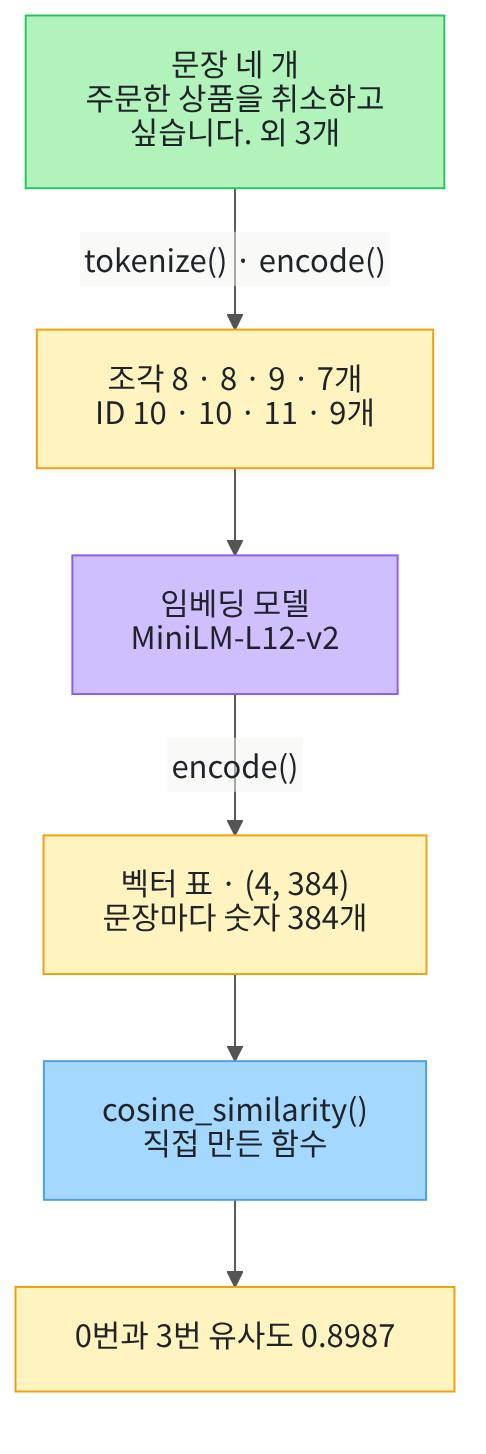

위에서 아래로 읽습니다. 초록 상자의 문장 네 개는 먼저 토큰으로 나뉘고, 보라 상자의 임베딩 모델이 문장마다 숫자 384개를 만듭니다.
파랑 상자는 이 노트북에서 직접 만드는 함수이고, 노란 상자는 출력으로 확인하는 값입니다.

## 1. 준비

이 절은 파일을 읽거나 만들지 않습니다. 준비 셀에서는 계산에 쓸 모듈 두 개를 불러오고 버전을 확인합니다.

표준 라이브러리 모듈 `math`는 제곱근 같은 수학 함수를 모아 둔 기능 묶음입니다.
패키지 sentence-transformers는 문장을 벡터로 바꾸는 모델을 불러오고 실행하게 해 줍니다.
함수 `warnings.filterwarnings()` 줄은 01절처럼 진행 표시 위젯이 없다는 경고 한 줄을 끕니다. 계산 결과와 관계없는 경고입니다.

In [1]:
# 계산에 쓸 math 모듈과 문장 임베딩 패키지를 불러오고 버전을 확인합니다
import math
import warnings

# 진행 표시 위젯이 없다는 경고(TqdmWarning)는 계산과 관계없어 화면에 내지 않습니다
warnings.filterwarnings("ignore", message="IProgress not found")

import sentence_transformers
from sentence_transformers import SentenceTransformer

print("sentence-transformers 버전:", sentence_transformers.__version__)

sentence-transformers 버전: 5.1.1


**결과 읽기** — 출력 줄은 `sentence-transformers 버전: 5.1.1`입니다. 준비물에 적은 기준 버전과 같습니다.

## 2. 임베딩 모델 준비

임베딩(embedding)은 글을 정해진 개수의 숫자 목록으로 바꾼 결과입니다. 지도에서 장소 하나를 위도와 경도 두 숫자로 적는 일과 비슷합니다.
이 절의 모델은 문장 하나를 숫자 384개로 적습니다. 순서가 정해진 숫자 목록을 벡터(vector)라고 부릅니다.

클래스 `SentenceTransformer(모델 이름, revision=판 번호)`는 01절의 `from_pretrained()`처럼 모델 파일을 받아 모델 객체를 만듭니다.
메서드 `get_sentence_embedding_dimension()`은 벡터 하나에 든 숫자 개수를 반환합니다. 속성 `max_seq_length`는 문장에서 읽는 최대 토큰 수입니다.

실행 전에 예상합니다. 여러 나라 말을 다루는 모델이니, 벡터의 숫자 개수는 수천 개쯤일 것 같습니다.

In [2]:
# 다국어 문장 임베딩 모델을 고정 판 번호로 받아 만들고, 벡터 크기를 확인합니다
model_name = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
model_revision = "e8f8c211226b894fcb81acc59f3b34ba3efd5f42"
# SentenceTransformer(모델 이름, revision=판 번호)는 모델 파일을 받아 모델 객체를 만듭니다
model = SentenceTransformer(model_name, revision=model_revision)
# 문장 하나를 숫자 몇 개로 나타내는지 반환합니다
dimension = model.get_sentence_embedding_dimension()
print("벡터의 숫자 개수:", dimension)
# 문장에서 앞부분부터 읽는 최대 토큰 수입니다
print("최대 토큰 수:", model.max_seq_length)

벡터의 숫자 개수: 384
최대 토큰 수: 128


**결과 읽기** — 벡터의 숫자 개수는 `384`이고, 최대 토큰 수는 `128`입니다. 예상보다 숫자 개수가 적습니다.

첫 실행에서는 모델 파일을 내려받는 진행 표시가 더 나올 수 있습니다. 숫자 개수 384는 모델 설정이 정한 값입니다.
다음 셀에서는 문장이 이 모델 안에서 먼저 어떤 토큰으로 나뉘는지 봅니다.

## 3. 문장 네 개를 토큰으로 나누기

임베딩 모델도 01절에서 본 것처럼 글을 먼저 토큰으로 나눕니다. 속성 `model.tokenizer`가 이 모델의 토큰화기이고, 메서드 `tokenize()`는 01절과 같습니다.
토큰화기의 메서드 `encode()`와 `convert_ids_to_tokens()`도 01절과 같습니다. 4절에서 쓰는 모델의 `encode()`와는 이름만 같습니다.

비교할 문장은 네 개입니다. 주문 취소 문장, 같은 뜻을 다른 낱말로 쓴 문장, 날씨 문장, 같은 뜻의 영어 문장입니다.
실행 전에 예상합니다. 문장 길이가 비슷하니 조각 수도 비슷하겠지만, 똑같지는 않을 것입니다.
01절 KLUE 토큰화기처럼 ID 수가 조각 수보다 많은지도 봅니다.

In [3]:
# 비교할 문장 네 개를 목록에 담고, 이 모델의 토큰화기로 문장마다 조각 수와 ID 수를 셉니다
sentences = [
    "주문한 상품을 취소하고 싶습니다.",
    "구매를 취소하려면 어떻게 하나요?",
    "내일 서울은 비가 옵니다.",
    "I want to cancel my order.",
]
for sentence in sentences:
    pieces = model.tokenizer.tokenize(sentence)
    # 모델에 넣는 것은 조각이 아니라 ID 목록입니다(01절)
    ids = model.tokenizer.encode(sentence)
    print("조각", len(pieces), "| ID", len(ids), "|", sentence)
first_ids = model.tokenizer.encode(sentences[0])
print("0번 문장의 ID를 되돌린 조각 목록:", model.tokenizer.convert_ids_to_tokens(first_ids))

조각 8 | ID 10 | 주문한 상품을 취소하고 싶습니다.
조각 8 | ID 10 | 구매를 취소하려면 어떻게 하나요?
조각 9 | ID 11 | 내일 서울은 비가 옵니다.
조각 7 | ID 9 | I want to cancel my order.
0번 문장의 ID를 되돌린 조각 목록: ['<s>', '▁주문', '한', '▁상품', '을', '▁취소', '하고', '▁싶습니다', '.', '</s>']


**결과 읽기** — 조각 수는 네 줄 차례로 `조각 8`, `조각 8`, `조각 9`, `조각 7`입니다. 예상대로 비슷하지만 같지는 않습니다.
ID 수는 `ID 10`, `ID 10`, `ID 11`, `ID 9`로, 네 줄 모두 조각 수보다 2개 많습니다.

마지막 줄의 목록은 `['<s>', '▁주문', '한', '▁상품', '을', '▁취소', '하고', '▁싶습니다', '.', '</s>']`입니다.
01절 KLUE의 `[CLS]`, `[SEP]`처럼, 이 토큰화기는 앞뒤에 특수 토큰 `<s>`와 `</s>`를 더했습니다. 조각 앞의 `▁` 표시는 그 앞에 공백이 있었다는 뜻입니다.
01절 GPT-2 조각의 `Ġ`와 뜻이 같고 모양만 다릅니다. KLUE 조각의 `##`은 반대로 공백 없이 이어진다는 표시였습니다.

## 4. 문장을 벡터로 바꾸기

메서드 `encode(문장 목록)`는 문장마다 숫자 384개를 한 줄로 담은 숫자 표를 반환합니다. 이 표는 NumPy라는 패키지의 배열(array)입니다.
Ch 4 01절의 데이터프레임처럼 속성 `shape`가 `(행 수, 열 수)`를 알려 줍니다. 표의 `vectors[0]`은 0번 행, 곧 0번 문장의 벡터입니다.

실행 전에 예상합니다. 3절에서 ID 수가 9~11개로 달랐으니, 벡터의 숫자 개수도 문장마다 다를 것 같습니다.

In [4]:
# 문장 네 개를 벡터로 바꾸고, 숫자 표의 모양과 0번 벡터의 앞 다섯 값을 봅니다
# encode(문장 목록)는 문장마다 숫자 384개를 한 행으로 담은 NumPy 배열을 반환합니다
vectors = model.encode(sentences)
print("벡터 표의 모양:", vectors.shape)
first_vector = vectors[0]
print("0번 벡터의 숫자 개수:", len(first_vector))
print("0번 벡터의 앞 다섯 값:", first_vector[0:5])
# 행 수는 넣은 문장 수, 열 수는 모델 설정이 정해서 매번 같습니다
assert vectors.shape == (4, 384)

벡터 표의 모양: (4, 384)
0번 벡터의 숫자 개수: 384
0번 벡터의 앞 다섯 값: [ 0.03628663  0.03654783  0.04329514 -0.10407412 -0.03251115]


**결과 읽기** — 벡터 표의 모양은 `(4, 384)`이고, 0번 벡터의 숫자 개수는 `384`입니다. 예상과 달리 ID 수가 달라도 벡터 크기는 모두 같습니다.

라벨 줄 끝의 앞 다섯 값은 `0.03628663`처럼 작은 소수이고, 음수도 섞여 있습니다.
숫자 하나만 보고는 취소인지 날씨인지 읽을 수 없습니다. 벡터 두 개를 비교해야 뜻이 가까운지 알 수 있습니다.

## 5. 숫자 두 개짜리 벡터로 계산 원리 보기

384개를 한꺼번에 보기 전에 숫자 두 개짜리 벡터로 계산을 익힙니다. 벡터 `[3, 4]`는 출발점에서 동쪽으로 3칸, 북쪽으로 4칸 간 화살표로 볼 수 있습니다.
두 화살표의 방향이 얼마나 같은지 나타내는 값을 코사인 유사도(cosine similarity)라고 부릅니다.

계산의 첫 단계는 점곱(dot product)입니다. 같은 자리의 숫자끼리 곱해 모두 더한 값입니다.
아래 함수 `dot_product()`는 반복 번호 `i`로 두 벡터의 같은 자리 숫자를 짝지어 곱합니다. 이 셀은 함수를 정의만 합니다.

In [5]:
# 두 벡터의 점곱(같은 자리 숫자끼리 곱해 모두 더한 값)을 반환하는 함수를 정의합니다
def dot_product(first, second):
    total = 0
    # 반복 번호 i로 두 벡터의 같은 자리 숫자를 짝지어 곱하고 더합니다
    for i in range(len(first)):
        total = total + first[i] * second[i]
    return total

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다. 다음 셀에서 화살표 두 개로 호출합니다.

실행 전에 예상합니다. 벡터 `[3, 4]`와 `[4, 3]`의 점곱은 3×4와 4×3을 더한 값입니다.

In [6]:
# 숫자 두 개짜리 벡터 두 개를 만들고 점곱을 계산합니다
first_arrow = [3, 4]
second_arrow = [4, 3]
arrow_dot = dot_product(first_arrow, second_arrow)
print("점곱:", arrow_dot)

점곱: 24


**결과 읽기** — 출력 줄은 `점곱: 24`입니다. 3×4 = 12와 4×3 = 12를 더한 값과 같습니다.

점곱은 방향이 비슷할수록 커지지만, 화살표가 길어져도 커집니다. 그래서 방향만 비교하려면 화살표의 길이로 나눕니다.

## 6. 벡터의 길이와 코사인 유사도

벡터의 길이는 숫자마다 제곱해 더한 뒤 제곱근을 구한 값입니다. 동쪽 3칸, 북쪽 4칸 떨어진 곳까지 곧게 가면 5칸이 되는 계산입니다.
숫자마다 제곱해 더한 값은 자기 자신과의 점곱과 같으므로, 앞에서 만든 `dot_product()`를 다시 씁니다.
함수 `math.sqrt(수)`는 제곱근을 반환합니다.

In [7]:
# 벡터의 길이(자기 자신과의 점곱에 제곱근을 씌운 값)를 반환하는 함수를 정의합니다
def vector_length(vector):
    # 자기 자신과의 점곱은 숫자마다 제곱해 더한 값입니다
    squared_sum = dot_product(vector, vector)
    # math.sqrt(수)는 제곱근을 반환합니다
    return math.sqrt(squared_sum)

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

이제 코사인 유사도 함수를 정의합니다. 점곱을 두 벡터 길이의 곱으로 나눈 값입니다.
방향이 똑같으면 1, 서로 직각이면 0에 가까워집니다.

In [8]:
# 두 벡터의 코사인 유사도(점곱을 두 길이의 곱으로 나눈 값)를 반환하는 함수를 정의합니다
def cosine_similarity(first, second):
    dot = dot_product(first, second)
    # 두 길이를 곱한 값으로 나누면 화살표 길이와 관계없이 방향만 비교합니다
    length_product = vector_length(first) * vector_length(second)
    return dot / length_product

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다. 다음 셀에서 길이와 유사도를 함께 계산합니다.

실행 전에 예상합니다. 두 화살표의 길이는 모두 5이고, 유사도는 24를 25로 나눈 값일 것입니다.
화살표 `[4, -3]`은 `[3, 4]`와 직각이라 점곱이 0이 됩니다.

In [9]:
# 화살표의 길이와, 세 가지 짝의 코사인 유사도를 계산합니다
print("[3, 4]의 길이:", vector_length(first_arrow))
print("[4, 3]의 길이:", vector_length(second_arrow))
cross_arrow = [4, -3]
similar_score = cosine_similarity(first_arrow, second_arrow)
print("[3, 4]와 [4, 3]:", similar_score)
self_score = cosine_similarity(first_arrow, first_arrow)
print("[3, 4]와 [3, 4]:", self_score)
cross_score = cosine_similarity(first_arrow, cross_arrow)
print("[3, 4]와 [4, -3]:", cross_score)

[3, 4]의 길이: 5.0
[4, 3]의 길이: 5.0
[3, 4]와 [4, 3]: 0.96
[3, 4]와 [3, 4]: 1.0
[3, 4]와 [4, -3]: 0.0


**결과 읽기** — 두 길이는 `5.0`입니다. 유사도는 `[3, 4]와 [4, 3]: 0.96`, `[3, 4]와 [3, 4]: 1.0`, `[3, 4]와 [4, -3]: 0.0`입니다.

방향이 거의 같은 짝은 1에 가깝고, 자기 자신은 정확히 1, 직각인 짝은 0입니다. 예상과 같습니다.

## 7. 문장 벡터의 코사인 유사도

같은 함수를 4절의 문장 벡터에 씁니다. 숫자가 384개로 늘었을 뿐 계산 방법은 같습니다.
0번 취소 문장을 기준으로 나머지 세 문장과 비교합니다. 함수 `round(값, 4)`는 Ch 2 04절에서처럼 소수 넷째 자리까지 반올림합니다.

실행 전에 예상합니다. 같은 한국어로 쓴 1번 문장이 영어로 쓴 3번 문장보다 0번과 더 가까울 것 같습니다.

In [10]:
# 0번 취소 문장과 나머지 세 문장의 코사인 유사도를 계산합니다
print("0번 문장:", sentences[0])
for number in range(1, len(sentences)):
    similarity = cosine_similarity(vectors[0], vectors[number])
    print("비교 문장", number, "| 유사도", round(similarity, 4), "|", sentences[number])

0번 문장: 주문한 상품을 취소하고 싶습니다.
비교 문장 1 | 유사도 0.8024 | 구매를 취소하려면 어떻게 하나요?
비교 문장 2 | 유사도 0.1044 | 내일 서울은 비가 옵니다.
비교 문장 3 | 유사도 0.8987 | I want to cancel my order.


**결과 읽기** — 세 줄은 차례로 `비교 문장 1 | 유사도 0.8024`, `비교 문장 2 | 유사도 0.1044`, `비교 문장 3 | 유사도 0.8987`입니다.

예상과 달리 영어 문장 3번이 0번과 가장 가깝습니다. 낱말이 하나도 겹치지 않지만, 이 모델은 같은 뜻이면 언어가 달라도 비슷한 방향의 벡터를 만들었습니다.
날씨 문장 2번은 0에 가까워, 두 화살표가 거의 직각입니다.

## 8. 정규화 — 길이를 1로 맞추기

정규화(normalization)는 벡터의 숫자를 모두 벡터 길이로 나눠, 길이를 1로 맞추는 일입니다. 화살표를 모두 한 뼘 길이로 자르고 방향만 남기는 일과 같습니다.
메서드 `encode()`에 인자 `normalize_embeddings=True`를 주면 정규화한 벡터를 반환합니다.

길이가 1인 벡터끼리는 길이의 곱도 1입니다. 그래서 점곱만 계산해도 코사인 유사도와 같은 값이 나올 것입니다.
실행 전에 예상합니다. 정규화한 0번·3번 벡터의 점곱은 7절의 0번·3번 유사도와 같을 것입니다.

In [11]:
# 같은 네 문장을 정규화한 벡터로 받고, 원래 벡터와 길이·점곱을 비교합니다
# normalize_embeddings=True를 주면 벡터마다 길이가 1이 되도록 나눈 값을 반환합니다
unit_vectors = model.encode(sentences, normalize_embeddings=True)
original_length = vector_length(vectors[0])
print("원래 0번 벡터의 길이:", round(original_length, 4))
unit_length = vector_length(unit_vectors[0])
print("정규화한 0번 벡터의 길이:", round(unit_length, 4))
unit_dot = dot_product(unit_vectors[0], unit_vectors[3])
print("정규화한 0번·3번 벡터의 점곱:", round(unit_dot, 4))

원래 0번 벡터의 길이: 3.9723
정규화한 0번 벡터의 길이: 1.0
정규화한 0번·3번 벡터의 점곱: 0.8987


**결과 읽기** — 원래 0번 벡터의 길이는 `3.9723`이고, 정규화한 0번 벡터의 길이는 `1.0`입니다. 정규화한 0번·3번 벡터의 점곱은 `0.8987`입니다.

예상대로 7절의 `유사도 0.8987`과 같습니다. 정규화한 벡터라면 점곱이 곧 코사인 유사도입니다.

## 9. 값 바꿔 보기 — 낱말 하나 바꾸기

0번 문장에서 낱말만 바꾼 두 문장을 만듭니다. 하나는 취소를 반품으로 바꾼 문장이고, 다른 하나는 뒤를 부정으로 바꾼 문장입니다.
바꾸는 값은 비교할 문장이고, 모델과 함수는 그대로입니다.

실행 전에 예상합니다. 반품 문장은 뜻이 다른 절차라 7절의 1번보다 낮을 것입니다.
부정문은 뜻이 반대이니, 날씨 문장만큼 낮을 것이라고 예상해 봅니다.

In [12]:
# 0번 문장의 낱말을 바꾼 두 문장을 벡터로 바꾸고, 0번 문장과의 유사도를 계산합니다
changed_sentences = ["주문한 상품을 반품하고 싶습니다.", "주문한 상품을 취소하고 싶지 않습니다."]
changed_vectors = model.encode(changed_sentences)
for number in range(len(changed_sentences)):
    similarity = cosine_similarity(vectors[0], changed_vectors[number])
    print("유사도", round(similarity, 4), "|", changed_sentences[number])

유사도 0.5931 | 주문한 상품을 반품하고 싶습니다.
유사도 0.6716 | 주문한 상품을 취소하고 싶지 않습니다.


**결과 읽기** — 반품 문장은 `유사도 0.5931`, 부정문은 `유사도 0.6716`입니다.

반품 문장은 예상대로 1번 문장보다 낮았습니다. 부정문은 예상과 달리 날씨 문장보다 훨씬 높고, 반품 문장보다도 높습니다.
이 모델은 낱말 대부분이 같은 부정문을 가깝게 두었습니다. 유사도가 높다고 같은 뜻이라고 판정할 수 없는 까닭입니다.

## 10. 앞에서 본 문장 쌍 비교하기

01절에서 토큰 수를 센 한국어·영어 문장 쌍을 벡터로 비교합니다. 이 쌍은 GPT-2 토큰화기에서 39토큰과 7토큰으로 크게 달랐습니다.
Ch 4 05절 기사 A10의 요약 글과, 같은 내용을 다른 낱말로 쓴 문장도 짝지었습니다.

목록 안의 튜플을 `for` 줄에서 두 이름으로 풀어 담는 모양은 01절 노트북의 8절과 같습니다.
실행 전에 예상합니다. 두 쌍 모두 뜻이 같으니 유사도가 0.8 안팎일 것입니다.

In [13]:
# 01절의 한국어·영어 문장 쌍과, Ch 4 기사 요약을 다른 낱말로 쓴 문장 쌍을 비교합니다
sentence_pairs = [
    ("오늘 주문 상태를 확인해 주세요.", "Please check today's order status."),
    ("주말 방문객 증가로 음식점 매출이 늘었습니다.", "주말에 식당 손님이 늘어 매출이 올랐습니다."),
]
for first_sentence, second_sentence in sentence_pairs:
    pair_vectors = model.encode([first_sentence, second_sentence])
    similarity = cosine_similarity(pair_vectors[0], pair_vectors[1])
    print("유사도", round(similarity, 4), "|", first_sentence, "|", second_sentence)

유사도 0.8312 | 오늘 주문 상태를 확인해 주세요. | Please check today's order status.


유사도 0.9517 | 주말 방문객 증가로 음식점 매출이 늘었습니다. | 주말에 식당 손님이 늘어 매출이 올랐습니다.


**결과 읽기** — 01절 문장 쌍은 `유사도 0.8312`, 기사 요약 쌍은 `유사도 0.9517`입니다.

두 쌍 모두 예상한 0.8 안팎보다 높았습니다. 토큰 수가 크게 다른 두 언어의 문장도, 낱말이 거의 다른 두 한국어 문장도 가까운 벡터가 되었습니다.
다만 문장 쌍 두 개로 본 결과라, 다른 문장에서도 늘 이렇게 높다고 볼 수는 없습니다.

## 정리

- 임베딩 모델은 문장을 토큰으로 나눈 뒤, 토큰 수와 관계없이 숫자 384개로 된 벡터 하나로 바꿨습니다.
- 코사인 유사도는 점곱을 두 길이의 곱으로 나눈 값입니다. 정규화한 벡터라면 점곱이 곧 코사인 유사도입니다.
- 0번 취소 문장과 영어 취소 문장은 0.8987, 날씨 문장은 0.1044였습니다. 부정문도 0.6716으로 반품 문장보다 높았습니다.

이번에는 모델 하나로 짧은 문장 열 개만 비교했습니다. 128토큰보다 긴 글, 다른 임베딩 모델, 검색 품질 측정은 실행하지 않았습니다.
다음 03절에서는 모델이 문장을 처리할 때 한 토큰이 다른 토큰 가운데 어느 쪽을 더 참고하는지 직관으로 봅니다.